In [ ]:
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from scipy.signal import butter, sosfiltfilt
from scipy.interpolate import Akima1DInterpolator
import numpy as np
import pywt

mpl.rcParams['font.family'] = 'arial'
mpl.rcParams['font.size'] = 10

colors = [
    '#8686D2',
    '#7BAED3',
    '#9CCBA0',
    '#E6DC84',
    '#D47291',
    '#868686',
]

In [545]:
data = pd.read_csv('../data/BTVIZ_2025-04-02.csv')
data.head()

C:\Users\y1hli\AppData\Local\Temp\ipykernel_21188\4079054614.py:1: DtypeWarning: Columns (3) have mixed types. Specify dtype option on import or set low_memory=False.
  data = pd.read_csv('../data/BTVIZ_2025-04-02.csv')


,id,timestamp,notificationTimestamp,deviceName,data_0,data_1,data_2,data_3,data_4,data_5
0,2025-04-02T13:58:02.657Z,1743602282657,28,NaN,1.0,2.0,5.0,6.0,6.0,4.0
1,2025-04-02T13:58:02.657Z,1743602282657,88,NaN,1.0,2.0,5.0,6.0,6.0,4.0
2,2025-04-02T13:58:02.657Z,1743602282657,88,NaN,1.0,2.0,5.0,6.0,6.0,4.0
3,2025-04-02T13:58:02.657Z,1743602282657,88,NaN,1.0,2.0,5.0,6.0,6.0,4.0
4,2025-04-02T13:58:02.657Z,1743602282657,106,NaN,1.0,2.0,5.0,6.0,6.0,4.0


In [546]:
timestamp = data.index.to_series().to_numpy()

channels = data.iloc[:, data.columns.str.startswith('data_')]
channels = channels.to_numpy()

sos1 = butter(4, 5, 'lowpass', fs=30, output='sos')
sos2 = butter(3, (0.5, 1.8), 'bandpass', fs=30, output='sos')

In [ ]:
def swt_drop_highfreq(channels, wavelet="db2", level=3, zero_levels=(1, 2)):
    """
    Stationary wavelet transform per channel, zero selected finest detail levels,
    inverse transform, crop back to original length.
    """
    X = np.asarray(channels, float)
    T, C = X.shape

    # Pad length to a multiple of 2**level (reflect)
    block = 2 ** level
    T_pad = int(np.ceil(T / block) * block)
    pad = T_pad - T

    Y = np.empty((T, C), dtype=float)

    # clamp requested zero_levels to available [1..level]
    zl = {l for l in zero_levels if 1 <= l <= level}

    for c in range(C):
        xc = X[:, c]
        if pad > 0:
            xc = np.pad(xc, (0, pad), mode="reflect")

        # SWT returns list [(cA1,cD1),...,(cAL,cDL)] with 1 = finest
        coeffs = pywt.swt(xc, wavelet=wavelet, level=level, norm=True)

        new_coeffs = []
        for j, (cA, cD) in enumerate(coeffs, start=1):
            if j in zl:
                cD = np.zeros_like(cD)  # drop finest details
            new_coeffs.append((cA, cD))

        xc_hat = pywt.iswt(new_coeffs, wavelet=wavelet, norm=True)

        # crop back to original length
        if pad > 0:
            xc_hat = xc_hat[:T]

        Y[:, c] = xc_hat

    return Y

In [548]:
channels_swt = swt_drop_highfreq(
    channels,
    wavelet="db2",
    level=3,
    zero_levels=(1, 2, 3)
)

channels_swt_f = sosfiltfilt(sos1, channels_swt, axis=0)
channels_swt_f = sosfiltfilt(sos2, channels_swt_f, axis=0)


In [549]:
t1 = 2450
t2 = 389100
d = 300

time_limits_1 = (t1, t1 + d)
time_limits_2 = (t2, t2 + d)

amplitude_limits = (-25, 25)

channels_swt_f_normalized = channels_swt_f.copy()

mask1 = (timestamp >= time_limits_1[0]) & (timestamp <= time_limits_1[1])
mask2 = (timestamp >= time_limits_2[0]) & (timestamp <= time_limits_2[1])
combined_mask = mask1 | mask2
                                           

for i in range(channels_swt_f.shape[1]):
    # Get data from both time regions
    region_data = channels_swt_f[combined_mask, i]
    
    if len(region_data) > 0:
        # Calculate min and max from both regions
        data_min = np.min(region_data)
        data_max = np.max(region_data)
        
        # Normalize to amplitude_limits range
        if data_max != data_min:  # Avoid division by zero
            channels_swt_f_normalized[:, i] = amplitude_limits[0] + (channels_swt_f[:, i] - data_min) * (amplitude_limits[1] - amplitude_limits[0]) / (data_max - data_min)
        else:
            channels_swt_f_normalized[:, i] = amplitude_limits[0]

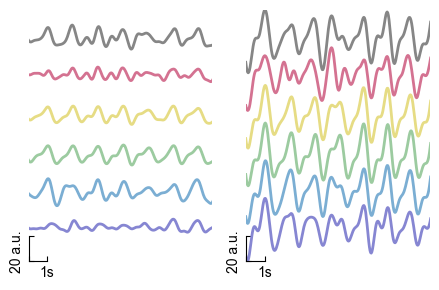

In [550]:
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(4.5, 3))

sample_rate = 30.0
z_offset = 30  # Small offset between channels

# Left subplot - first time region
ax_left = axes[0]
for i in range(channels_swt_f_normalized.shape[1]):
    y = channels_swt_f_normalized[:, i] + i * z_offset
    ax_left.plot(timestamp, y, color=colors[i], alpha=1, linewidth=2)

ax_left.set_xlim(*time_limits_1)
ax_left.set_ylim(amplitude_limits[0], amplitude_limits[1] + 5 * z_offset)

# Set spine bounds to show only scale bar segments
# Bottom spine: show only 1 second (30 samples)
ax_left.spines['bottom'].set_bounds(time_limits_1[0], time_limits_1[0] + 30)
# Left spine: show only 20 units
ax_left.spines['left'].set_bounds(amplitude_limits[0], amplitude_limits[0] + 20)

# Hide top and right spines
ax_left.spines['top'].set_visible(False)
ax_left.spines['right'].set_visible(False)

# Set custom ticks for the scale bars
ax_left.set_xticks([time_limits_1[0], time_limits_1[0] + 30])
ax_left.set_xticklabels(['', '1s'])
ax_left.set_yticks([amplitude_limits[0], amplitude_limits[0] + 20])
ax_left.set_yticklabels(['', '20 a.u.'], rotation=90)

ax_left.tick_params(axis='both', which='both', direction='in')

# Right subplot - second time region
ax_right = axes[1]
for i in range(channels_swt_f_normalized.shape[1]):
    y = channels_swt_f_normalized[:, i] + i * z_offset
    ax_right.plot(timestamp, y, color=colors[i], alpha=1, linewidth=2)

ax_right.set_xlim(*time_limits_2)
ax_right.set_ylim(amplitude_limits[0], amplitude_limits[1] + 5 * z_offset)

# Set spine bounds to show only scale bar segments
# Bottom spine: show only 1 second (30 samples)
ax_right.spines['bottom'].set_bounds(time_limits_2[0], time_limits_2[0] + 30)
# Left spine: show only 20 units
ax_right.spines['left'].set_bounds(amplitude_limits[0], amplitude_limits[0] + 20)

# Hide top and right spines
ax_right.spines['top'].set_visible(False)
ax_right.spines['right'].set_visible(False)

# Set custom ticks for the scale bars
ax_right.set_xticks([time_limits_2[0], time_limits_2[0] + 30])
ax_right.set_xticklabels(['', '1s'])
ax_right.set_yticks([amplitude_limits[0], amplitude_limits[0] + 20])
ax_right.set_yticklabels(['', '20 a.u.'], rotation=90)

ax_right.tick_params(axis='both', which='both', direction='in')

plt.tight_layout()
# plt.savefig('../figures/fig1/mode_a_sample.png', dpi=600, bbox_inches='tight')
plt.show()
